In [103]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

## Введение

Прогнозирование электрической нагрузки является важной задачей для энергетических систем, поскольку точность прогнозов напрямую влияет на планирование генерации, устойчивость энергосети и операционные затраты. Потребление электроэнергии представляет собой сложный временной ряд, формируемый поведенческими, сезонными и внешними факторами.

В данном проекте рассматривается задача **краткосрочного прогнозирования электрической нагрузки** на основе исторических почасовых данных энергопотребления оператора **PJM Interconnection**. Целью является прогноз значения нагрузки **на 24 часа вперёд** (day-ahead forecasting) с использованием только прошлых наблюдений и календарных признаков.

Данные охватывают длительный временной период и характеризуются выраженной суточной, недельной и годовой сезонностью, нестационарным поведением и наличием экстремальных значений. Эти особенности ограничивают применение классических временных моделей и мотивируют использование методов машинного обучения с лаговыми и календарными признаками.

Проект включает этапы разведочного анализа данных (EDA), генерации признаков, построения базовых моделей и применения алгоритмов градиентного бустинга (XGBoost и CatBoost). Качество прогнозирования оценивается в постановке **direct multi-step forecasting** с фиксированным горизонтом 24 часа.

# EDA

In [ ]:
DATA_PATH = "PJME_hourly.csv"  

df = pd.read_csv(DATA_PATH)
df["Datetime"] = pd.to_datetime(df["Datetime"])
df = df.sort_values("Datetime").reset_index(drop=True)

df.head()

,Datetime,PJME_MW
0,2002-01-01 01:00:00,30393.0
1,2002-01-01 02:00:00,29265.0
2,2002-01-01 03:00:00,28357.0
3,2002-01-01 04:00:00,27899.0
4,2002-01-01 05:00:00,28057.0


In [109]:
print("Rows:", len(df))
print("Start:", df["Datetime"].min())
print("End:", df["Datetime"].max())

print("\nMissing values:\n", df.isna().sum())

print("\nDuplicates by Datetime:", df["Datetime"].duplicated().sum())

print("\nTarget describe:\n", df["PJME_MW"].describe())

Rows: 145366
Start: 2002-01-01 01:00:00
End: 2018-08-03 00:00:00

Missing values:
 Datetime    0
PJME_MW     0
dtype: int64

Duplicates by Datetime: 4

Target describe:
 count    145366.000000
mean      32080.222831
std        6464.012166
min       14544.000000
25%       27573.000000
50%       31421.000000
75%       35650.000000
max       62009.000000
Name: PJME_MW, dtype: float64


В данных присутствуют редкие дубликаты временных меток, обусловленные переходами на летнее и зимнее время (DST). Данные наблюдения были сохранены, так как они представляют реальные измерения энергопотребления и не являются ошибками сбора данных.

In [112]:
assert set(["Datetime", "PJME_MW"]).issubset(df.columns)
assert df["Datetime"].isna().sum() == 0
assert df["PJME_MW"].isna().sum() == 0
assert df["Datetime"].is_monotonic_increasing, "Datetime должен быть отсортирован по возрастанию"
assert df["PJME_MW"].dtype != "O", "PJME_MW не должен быть строкой"
print("OK, базовые проверки прошли")

OK, базовые проверки прошли


In [114]:
# Ожидаем частоту 1H
dt = df["Datetime"].diff().dropna()
print("Most common step:", dt.value_counts().head(5))

# Найдем "дыры" (не 1 час)
gaps = df.loc[df["Datetime"].diff() != pd.Timedelta(hours=1), ["Datetime"]].head(20)
print("\nFirst non-1H steps:\n", gaps)

Most common step: Datetime
0 days 01:00:00    145331
0 days 02:00:00        30
0 days 00:00:00         4
Name: count, dtype: int64

First non-1H steps:
                  Datetime
0     2002-01-01 01:00:00
2306  2002-04-07 04:00:00
7176  2002-10-27 03:00:00
11040 2003-04-06 04:00:00
15910 2003-10-26 03:00:00
19774 2004-04-04 04:00:00
24812 2004-10-31 03:00:00
28508 2005-04-03 04:00:00
33546 2005-10-30 03:00:00
37242 2006-04-02 04:00:00
42280 2006-10-29 03:00:00
45472 2007-03-11 04:00:00
51182 2007-11-04 03:00:00
54206 2008-03-09 04:00:00
59916 2008-11-02 03:00:00
62940 2009-03-08 04:00:00
68650 2009-11-01 03:00:00
71842 2010-03-14 04:00:00
77552 2010-11-07 03:00:00
78341 2010-12-10 01:00:00


Анализ временного шага показал редкие отклонения от почасовой частоты, выраженные в шагах 0 и 2 часа. Эти отклонения соответствуют переходам на летнее и зимнее время (Daylight Saving Time) и являются ожидаемыми для энергетических данных в США. В связи с этим данные не подвергались дополнительной очистке.

In [117]:
df["hour"] = df["Datetime"].dt.hour
df["dayofweek"] = df["Datetime"].dt.dayofweek
df["month"] = df["Datetime"].dt.month

hour_mean = df.groupby("hour")["PJME_MW"].mean()
dow_mean = df.groupby("dayofweek")["PJME_MW"].mean()
month_mean = df.groupby("month")["PJME_MW"].mean()

print("Min hour mean at hour:", hour_mean.idxmin())
print("Max hour mean at hour:", hour_mean.idxmax())

print("Min DOW mean at:", dow_mean.idxmin(), "(0=Mon)")
print("Max DOW mean at:", dow_mean.idxmax(), "(0=Mon)")

print("Min month mean at:", month_mean.idxmin())
print("Max month mean at:", month_mean.idxmax())

Min hour mean at hour: 4
Max hour mean at hour: 19
Min DOW mean at: 6 (0=Mon)
Max DOW mean at: 1 (0=Mon)
Min month mean at: 4
Max month mean at: 7


In [118]:
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["font.size"] = 11

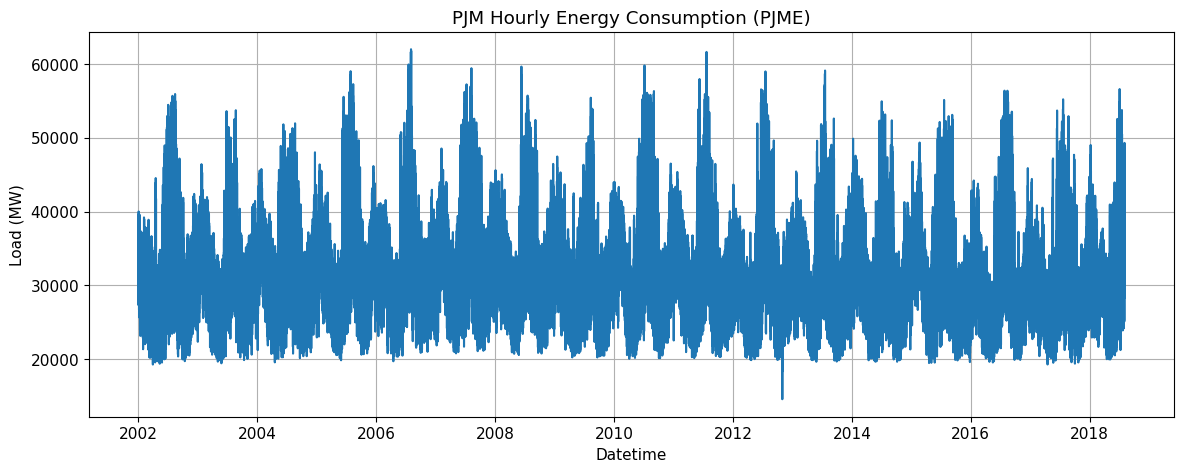

In [121]:
plt.figure()
plt.plot(df["Datetime"], df["PJME_MW"])
plt.xlabel("Datetime")
plt.ylabel("Load (MW)")
plt.title("PJM Hourly Energy Consumption (PJME)")
plt.show()

In [122]:
df["year"] = df["Datetime"].dt.year
df["month"] = df["Datetime"].dt.month
df["dayofmonth"] = df["Datetime"].dt.day
df["dayofweek"] = df["Datetime"].dt.dayofweek  # 0=Mon
df["hour"] = df["Datetime"].dt.hour
df["date"] = df["Datetime"].dt.date
df['dayofyear'] = df["Datetime"].dt.dayofyear

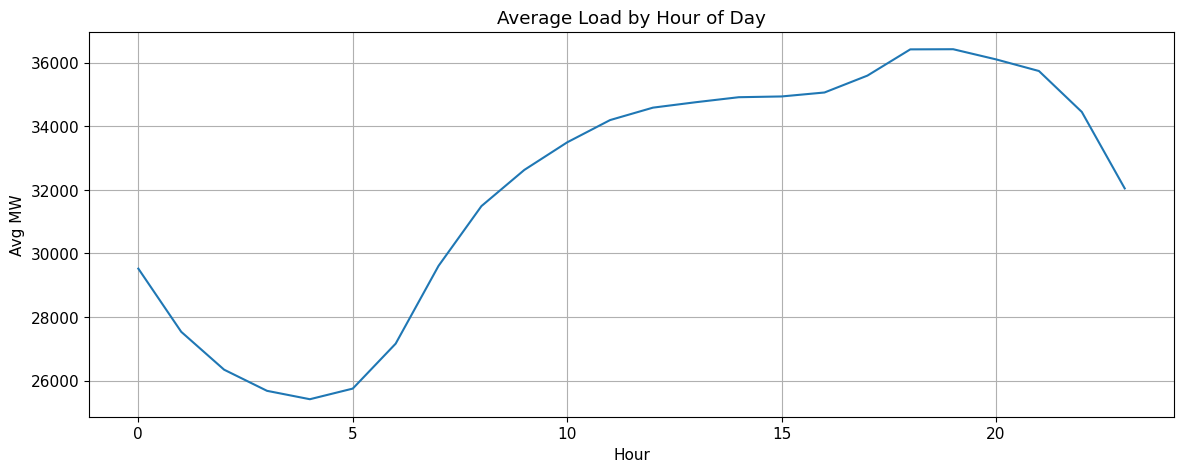

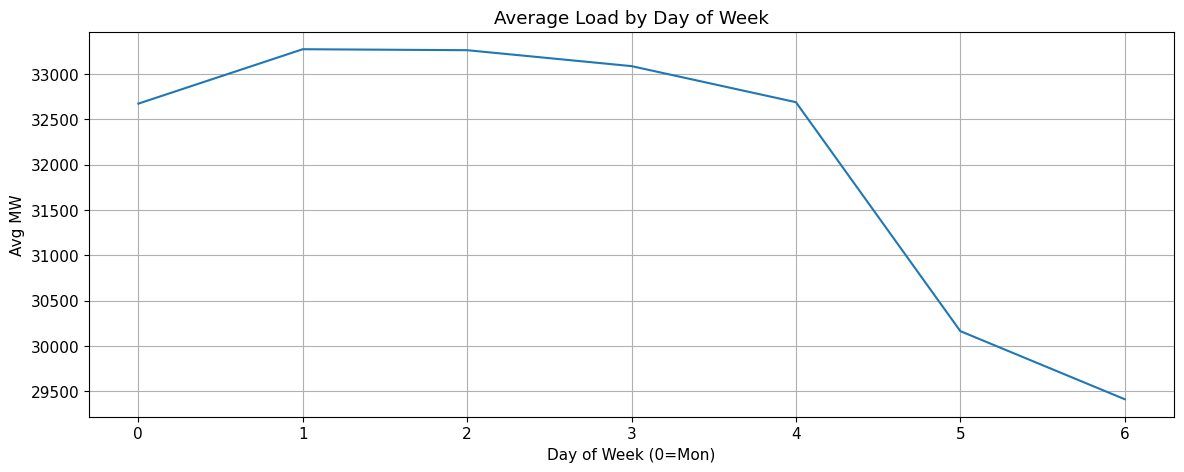

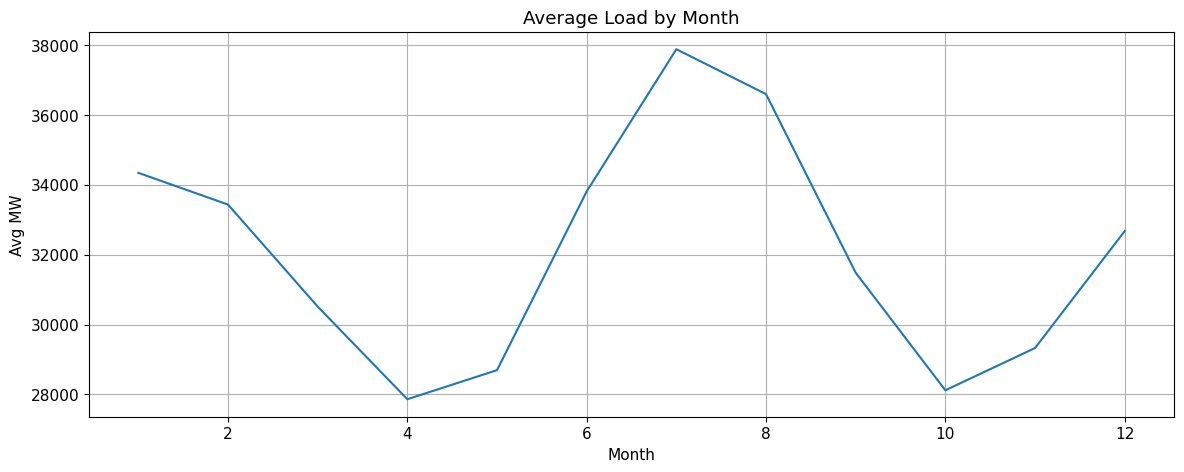

In [123]:
hour_mean = df.groupby("hour")["PJME_MW"].mean()
dow_mean = df.groupby("dayofweek")["PJME_MW"].mean()
month_mean = df.groupby("month")["PJME_MW"].mean()

plt.figure()
plt.plot(hour_mean.index, hour_mean.values)
plt.xlabel("Hour")
plt.ylabel("Avg MW")
plt.title("Average Load by Hour of Day")
plt.show()

plt.figure()
plt.plot(dow_mean.index, dow_mean.values)
plt.xlabel("Day of Week (0=Mon)")
plt.ylabel("Avg MW")
plt.title("Average Load by Day of Week")
plt.show()

plt.figure()
plt.plot(month_mean.index, month_mean.values)
plt.xlabel("Month")
plt.ylabel("Avg MW")
plt.title("Average Load by Month")
plt.show()

In [126]:
q1 = df["PJME_MW"].quantile(0.25)
q3 = df["PJME_MW"].quantile(0.75)
iqr = q3 - q1

low_thr = q1 - 1.5 * iqr
high_thr = q3 + 1.5 * iqr

outliers = df[(df["PJME_MW"] < low_thr) | (df["PJME_MW"] > high_thr)].copy()
print("Outliers count:", len(outliers))
outliers.sort_values("PJME_MW").head(10), outliers.sort_values("PJME_MW", ascending=False).head(10)

Outliers count: 3455


(                  Datetime  PJME_MW  hour  dayofweek  month  year  dayofmonth  \
 94901  2012-10-30 04:00:00  14544.0     4          1     10  2012          30   
 94900  2012-10-30 03:00:00  14586.0     3          1     10  2012          30   
 94902  2012-10-30 05:00:00  14821.0     5          1     10  2012          30   
 94899  2012-10-30 02:00:00  14955.0     2          1     10  2012          30   
 94898  2012-10-30 01:00:00  15390.0     1          1     10  2012          30   
 144660 2018-07-04 15:00:00  47767.0    15          2      7  2018           4   
 101268 2013-07-22 13:00:00  47768.0    13          0      7  2013          22   
 57147  2008-07-09 17:00:00  47770.0    17          2      7  2008           9   
 4426   2002-07-04 12:00:00  47776.0    12          3      7  2002           4   
 40518  2006-08-16 16:00:00  47776.0    16          2      8  2006          16   
 
               date  dayofyear  
 94901   2012-10-30        304  
 94900   2012-10-30        304

Для анализа экстремальных значений нагрузки было использовано правило межквартильного размаха (IQR). Анализ показал наличие редких, но значительных пиков потребления, которые соответствуют реальным режимам работы энергосистемы. Ввиду прикладного характера задачи данные наблюдения не рассматривались как выбросы для удаления, а были сохранены в обучающей выборке.

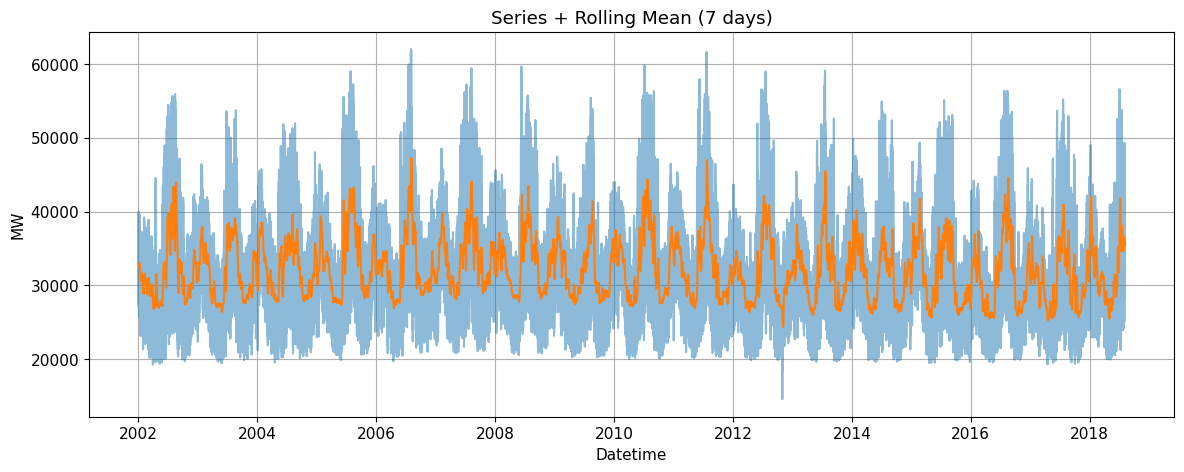

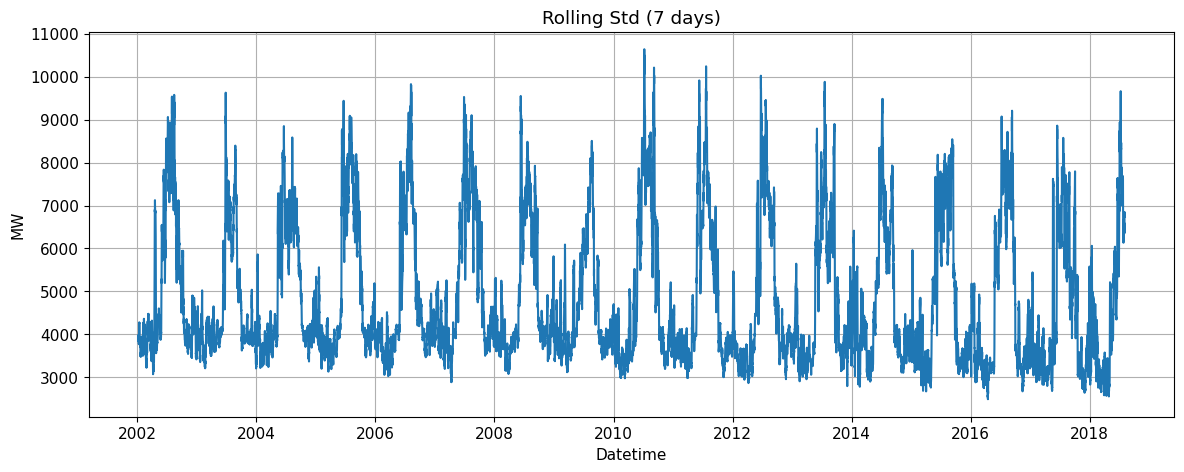

In [130]:
# 7 дней = 7*24 часов
window = 7 * 24

roll_mean = df["PJME_MW"].rolling(window=window).mean()
roll_std = df["PJME_MW"].rolling(window=window).std()

plt.figure()
plt.plot(df["Datetime"], df["PJME_MW"], alpha=0.5)
plt.plot(df["Datetime"], roll_mean)
plt.xlabel("Datetime")
plt.ylabel("MW")
plt.title("Series + Rolling Mean (7 days)")
plt.show()

plt.figure()
plt.plot(df["Datetime"], roll_std)
plt.xlabel("Datetime")
plt.ylabel("MW")
plt.title("Rolling Std (7 days)")
plt.show()

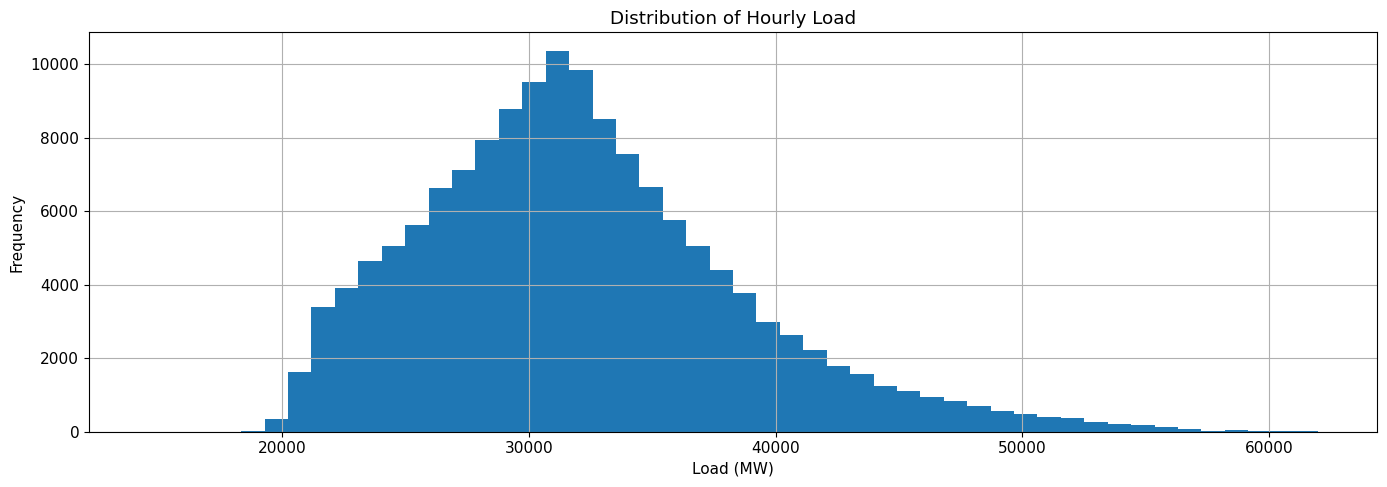

In [131]:
plt.figure()
plt.hist(df["PJME_MW"], bins=50)
plt.xlabel("Load (MW)")
plt.ylabel("Frequency")
plt.title("Distribution of Hourly Load")
plt.tight_layout()
plt.show()

<Figure size 1400x500 with 0 Axes>

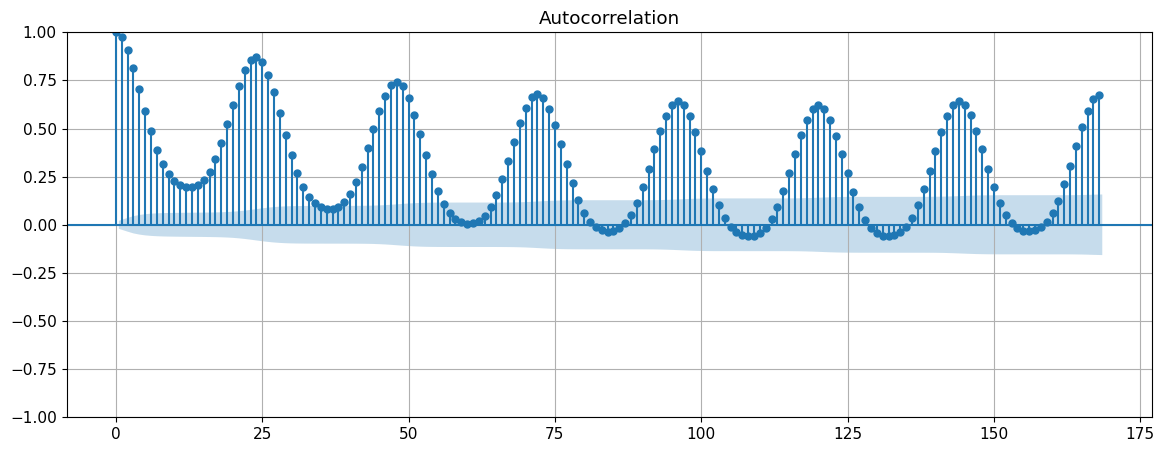

<Figure size 1400x500 with 0 Axes>

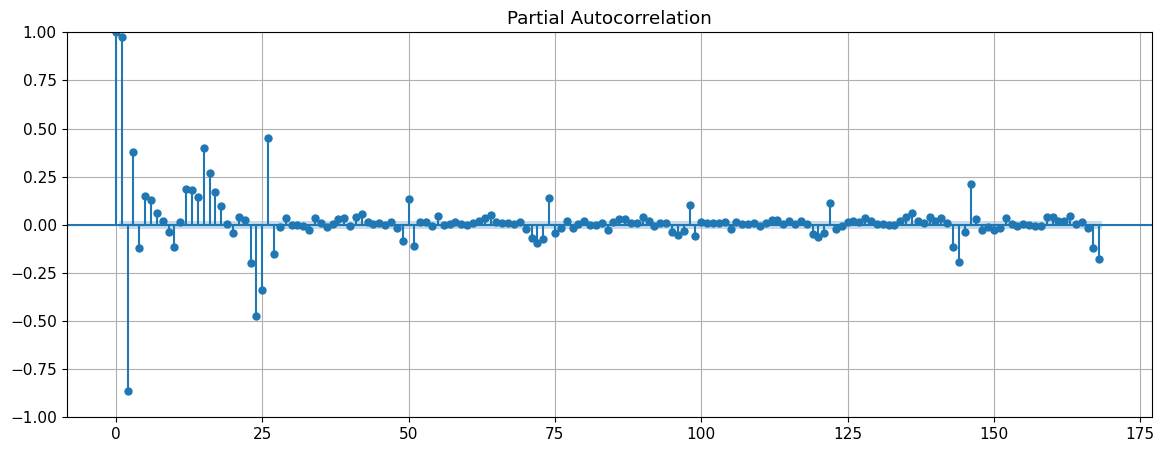

In [134]:
# Для скорости берем сэмпл (например, 1 год) или ограничим лаги
sample = df.set_index("Datetime")["PJME_MW"].loc["2017-01-01":"2017-12-31"]

plt.figure()
plot_acf(sample, lags=7*24)  # до недели лагов
plt.show()

plt.figure()
plot_pacf(sample, lags=7*24, method="ywm")
plt.show()

Анализ автокорреляционной (ACF) и частной автокорреляционной (PACF) функций показывает высокую инерционность временного ряда и наличие выраженной суточной сезонности, проявляющейся в периодических пиках автокорреляции с периодом 24 часа. PACF указывает на доминирующую роль первого лага, а также на наличие дополнительных сезонных зависимостей. Эти результаты послужили обоснованием для использования лаговых признаков (lag_24, lag_168) и отказа от краткосрочных лагов в задаче multi-step прогнозирования.

In [141]:
df_short = df.set_index("Datetime").loc["2016-07-01":"2016-07-14"]["PJME_MW"]

decomp_hourly = seasonal_decompose(
    df_short,
    model="additive",
    period=24
)

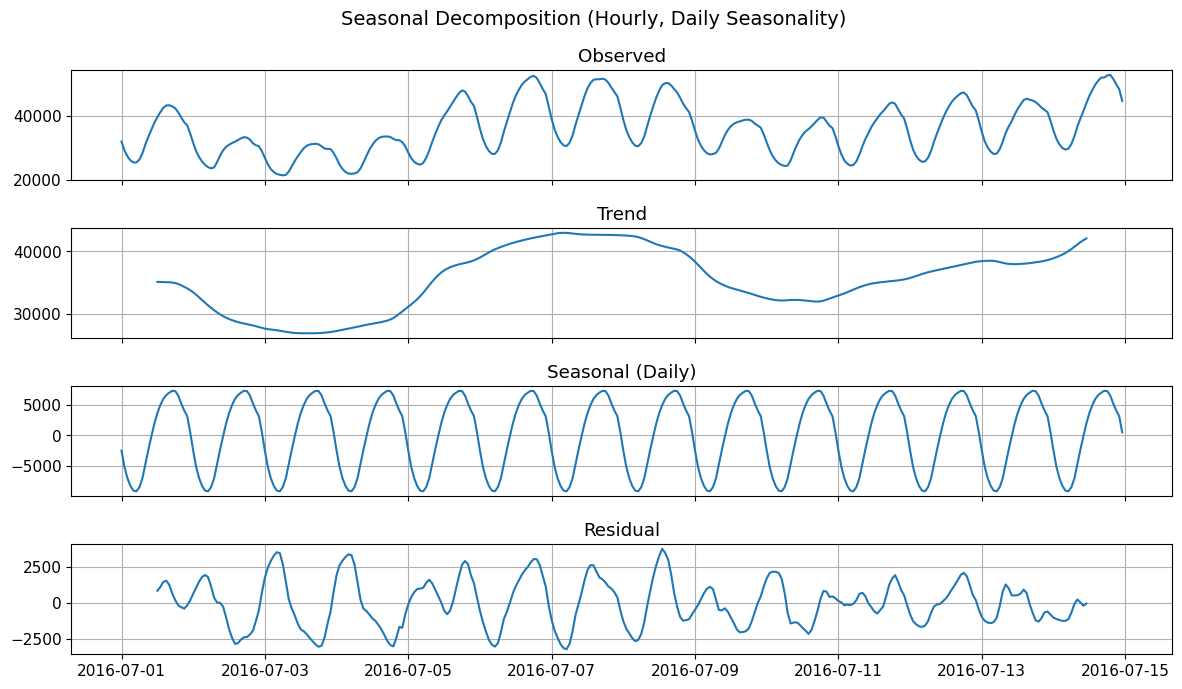

In [143]:
fig, axes = plt.subplots(4, 1, figsize=(12, 7), sharex=True)

axes[0].plot(decomp_hourly.observed)
axes[0].set_title("Observed")

axes[1].plot(decomp_hourly.trend)
axes[1].set_title("Trend")

axes[2].plot(decomp_hourly.seasonal)
axes[2].set_title("Seasonal (Daily)")

axes[3].plot(decomp_hourly.resid)
axes[3].set_title("Residual")

plt.suptitle("Seasonal Decomposition (Hourly, Daily Seasonality)", fontsize=14)
plt.tight_layout()
plt.show()

In [145]:
def adf_test(series, name="series"):
    series = series.dropna()
    res = adfuller(series, autolag="AIC")
    out = {
        "name": name,
        "adf_stat": res[0],
        "p_value": res[1],
        "n_lags": res[2],
        "n_obs": res[3],
    }
    return out

# ADF на исходном ряде (может быть нестационарен из-за сезонности)
print(adf_test(df["PJME_MW"], "PJME_MW"))

# ADF на разностях (часто более стационарно)
print(adf_test(df["PJME_MW"].diff(), "diff_1"))

{'name': 'PJME_MW', 'adf_stat': -19.88134841399188, 'p_value': 0.0, 'n_lags': 75, 'n_obs': 145290}
{'name': 'diff_1', 'adf_stat': -54.377690296630455, 'p_value': 0.0, 'n_lags': 74, 'n_obs': 145290}


Несмотря на то, что ADF-тест формально отвергает гипотезу о нестационарности (p-value ≈ 0), визуальный анализ и сезонная декомпозиция показывают наличие выраженных трендов и сезонных компонент. Это указывает на ограниченность стандартных тестов стационарности для длинных почасовых временных рядов и мотивирует использование моделей машинного обучения, не требующих строгой стационарности данных.

Дифференцирование и классические ARIMA-подходы не являются очевидным выбором.

In [146]:
eda_summary = {
    "rows": len(df),
    "start": str(df["Datetime"].min()),
    "end": str(df["Datetime"].max()),
    "missing": df.isna().sum().to_dict(),
    "dup_datetimes": int(df["Datetime"].duplicated().sum()),
    "mean": float(df["PJME_MW"].mean()),
    "std": float(df["PJME_MW"].std()),
    "min": float(df["PJME_MW"].min()),
    "max": float(df["PJME_MW"].max()),
}

eda_summary

{'rows': 145366,
 'start': '2002-01-01 01:00:00',
 'end': '2018-08-03 00:00:00',
 'missing': {'Datetime': 0,
  'PJME_MW': 0,
  'hour': 0,
  'dayofweek': 0,
  'month': 0,
  'year': 0,
  'dayofmonth': 0,
  'date': 0,
  'dayofyear': 0},
 'dup_datetimes': 4,
 'mean': 32080.222830648156,
 'std': 6464.012166412719,
 'min': 14544.0,
 'max': 62009.0}

# Feature engineering

In [148]:
# Лаговые признаки
for lag in [24, 48, 144, 168]:
    df[f"lag_{lag}"] = df["PJME_MW"].shift(lag)

# Календарные признаки
df["hour"] = df["Datetime"].dt.hour
df["dayofweek"] = df["Datetime"].dt.dayofweek
df["month"] = df["Datetime"].dt.month

df.tail()

,Datetime,PJME_MW,hour,dayofweek,month,year,dayofmonth,date,dayofyear,lag_24,lag_48,lag_144,lag_168
145361,2018-08-02 20:00:00,44057.0,20,3,8,2018,2,2018-08-02,214,46912.0,40289.0,40883.0,46337.0
145362,2018-08-02 21:00:00,43256.0,21,3,8,2018,2,2018-08-02,214,45985.0,39938.0,39275.0,44542.0
145363,2018-08-02 22:00:00,41552.0,22,3,8,2018,2,2018-08-02,214,44094.0,38610.0,37618.0,42638.0
145364,2018-08-02 23:00:00,38500.0,23,3,8,2018,2,2018-08-02,214,40666.0,35950.0,35038.0,39276.0
145365,2018-08-03 00:00:00,35486.0,0,4,8,2018,3,2018-08-03,215,37158.0,33072.0,32468.0,35742.0


Данные были разделены на обучающую и тестовую выборки с использованием временного разбиения (time-based split) для предотвращения утечки данных. Обучающая выборка охватывает период 2002–2016 гг., а тестовая — 2017–2018 гг., что соответствует реальному сценарию прогнозирования.

В отличие от стандартного one-step-ahead прогнозирования, в работе была рассмотрена задача multi-step forecasting с горизонтом 24 часа. Такой подход существенно усложняет задачу и приближает её к реальным сценариям планирования энергосистем, позволяя более корректно оценить обобщающую способность моделей.

In [151]:
HORIZON = 24  # 24 часа вперёд

df_ms = df.copy()
df_ms["target_t+24"] = df_ms["PJME_MW"].shift(-HORIZON)

FEATURES = [
    "hour", "dayofweek", "month",
    "lag_24", "lag_48", "lag_144", "lag_168"
]

В процессе предварительного анализа были сформированы расширенные календарные признаки для изучения сезонных закономерностей временного ряда. По результатам EDA и анализа автокорреляции для моделирования были отобраны только те признаки, которые отражают устойчивые периодические зависимости и улучшают качество прогнозирования. В итоговую модель вошли признаки hour, dayofweek и month, тогда как признаки year, dayofmonth, dayofyear и date были исключены как избыточные или неинформативные для задачи краткосрочного прогнозирования.

In [153]:
df_ms = df_ms.dropna().reset_index(drop=True) #удаляем строки с NaN (из-за лагов)
print("Original:", len(df))
print("After dropna (multi-step):", len(df_ms))

Original: 145366
After dropna (multi-step): 145174


# Train/Test Split

In [155]:
train = df_ms[df_ms["Datetime"] < "2017-01-01"]
test  = df_ms[df_ms["Datetime"] >= "2017-01-01"]

print("Train:", train.shape)
print("Test :", test.shape)

Train: (131302, 14)
Test : (13872, 14)


In [156]:
TARGET = "target_t+24"

X_train = train[FEATURES]
y_train = train[TARGET]

X_test  = test[FEATURES]

y_test  = test[TARGET]

In [164]:
df_ms[["Datetime", "PJME_MW", "target_t+24"]].head(3), \
df_ms[["Datetime", "PJME_MW", "target_t+24"]].tail(3)

(             Datetime  PJME_MW  target_t+24
 0 2002-01-08 01:00:00  29445.0      29082.0
 1 2002-01-08 02:00:00  28670.0      28154.0
 2 2002-01-08 03:00:00  28375.0      27829.0,
                   Datetime  PJME_MW  target_t+24
 145171 2018-08-01 22:00:00  44094.0      41552.0
 145172 2018-08-01 23:00:00  40666.0      38500.0
 145173 2018-08-02 00:00:00  37158.0      35486.0)

# Model training

### Baseline models

In [168]:
y_pred_naive = X_test["lag_24"]

mae_naive = (y_test - y_pred_naive).abs().mean()
rmse_naive = ((y_test - y_pred_naive) ** 2).mean() ** 0.5

print("Naive multi-step (24h ahead)")
print("MAE :", mae_naive)
print("RMSE:", rmse_naive)

Naive multi-step (24h ahead)
MAE : 3352.001585928489
RMSE: 4443.760088505299


Для задачи multi-step forecasting с горизонтом 24 часа был использован наивный baseline, предполагающий, что нагрузка через 24 часа равна нагрузке в тот же час предыдущего дня. Данный подход показал RMSE ≈ 4.4 ГВт, что подчёркивает значительно более высокую сложность multi-step прогнозирования по сравнению с one-step задачей.

In [171]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

mae_lr = (y_test - y_pred_lr).abs().mean()
rmse_lr = ((y_test - y_pred_lr) ** 2).mean() ** 0.5

print("Linear Regression")
print("MAE :", mae_lr)
print("RMSE:", rmse_lr)

Linear Regression
MAE : 2814.6569392460137
RMSE: 3705.863756830411


В задаче multi-step forecasting с горизонтом 24 часа линейная регрессия показала улучшение по сравнению с наивным baseline (RMSE снизился с ~4.4 ГВт до ~3.9 ГВт). Это указывает на способность модели учитывать суточную и недельную сезонность, однако сохраняющаяся ошибка свидетельствует о наличии нелинейных зависимостей, ограничивающих качество линейной модели.

## XGBoost Model

Классические модели временных рядов, такие как SARIMA, являются эффективным инструментом для прогнозирования временных рядов с одной доминирующей сезонностью и относительно простой структурой. Однако в задаче почасового прогнозирования энергопотребления присутствуют несколько выраженных сезонных компонентов (суточная и недельная), а также значительная нелинейность и изменяющаяся дисперсия. В связи с этим были выбраны модели машинного обучения, способные более гибко учитывать сложную структуру данных.

In [176]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)

mae_xgb = (y_test - y_pred_xgb).abs().mean()
rmse_xgb = ((y_test - y_pred_xgb) ** 2).mean() ** 0.5

print("XGBoost (multi-step, 24h ahead)")
print("MAE :", mae_xgb)
print("RMSE:", rmse_xgb)

XGBoost (multi-step, 24h ahead)
MAE : 2574.2125949529627
RMSE: 3418.568621581572


Градиентный бустинг (XGBoost) показал наилучшее качество среди рассмотренных моделей в задаче multi-step forecasting с горизонтом 24 часа, существенно превзойдя наивный baseline и линейную регрессию. Это подтверждает наличие нелинейных зависимостей и сложной сезонной структуры во временном ряду энергопотребления.

In [178]:
plot_df = test.copy()
plot_df["y_true"] = y_test.values
plot_df["y_pred"] = y_pred_xgb

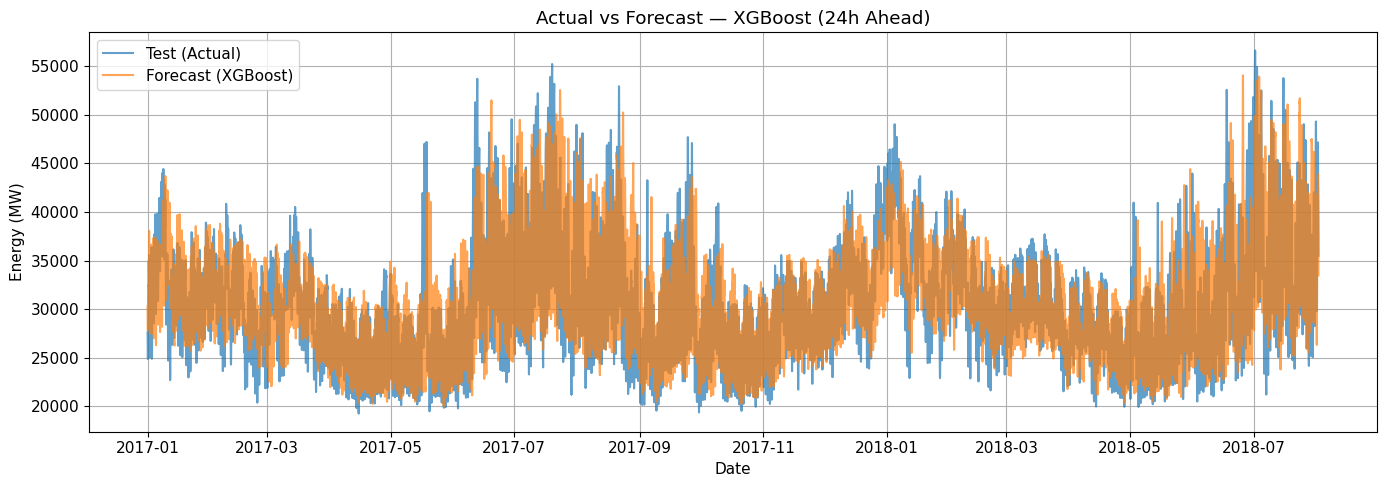

In [179]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    plot_df["Datetime"],
    plot_df["y_true"],
    label="Test (Actual)",
    alpha=0.7
)

plt.plot(
    plot_df["Datetime"],
    plot_df["y_pred"],
    label="Forecast (XGBoost)",
    alpha=0.7
)

plt.xlabel("Date")
plt.ylabel("Energy (MW)")
plt.title("Actual vs Forecast — XGBoost (24h Ahead)")
plt.legend()
plt.tight_layout()
plt.show()

In [183]:
import pandas as pd
import matplotlib.pyplot as plt

importance = xgb.feature_importances_

fi = pd.DataFrame({
    "feature": FEATURES,
    "importance": importance
}).sort_values("importance", ascending=False)

fi

,feature,importance
5,lag_144,0.475553
3,lag_24,0.279784
1,dayofweek,0.086829
0,hour,0.056672
6,lag_168,0.035066
2,month,0.034944
4,lag_48,0.031151


In [185]:
from catboost import CatBoostRegressor

cat = CatBoostRegressor(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="RMSE",
    random_seed=42,
    verbose=100
)

cat.fit(X_train, y_train)

y_pred_cat = cat.predict(X_test)

mae_cat = (y_test - y_pred_cat).abs().mean()
rmse_cat = ((y_test - y_pred_cat) ** 2).mean() ** 0.5

print("CatBoost (multi-step, 24h ahead)")
print("MAE :", mae_cat)
print("RMSE:", rmse_cat)

0:	learn: 6278.9395789	total: 206ms	remaining: 1m 42s
100:	learn: 2962.9655479	total: 1.12s	remaining: 4.42s
200:	learn: 2857.3524623	total: 2.06s	remaining: 3.06s
300:	learn: 2798.8423618	total: 3s	remaining: 1.98s
400:	learn: 2760.4983058	total: 3.95s	remaining: 975ms
499:	learn: 2730.3395142	total: 4.89s	remaining: 0us
CatBoost (multi-step, 24h ahead)
MAE : 2556.2379133031727
RMSE: 3361.2574090975154


Для оценки устойчивости результатов была дополнительно рассмотрена модель CatBoost как альтернативная реализация градиентного бустинга. Результаты показали сопоставимое качество прогнозирования по сравнению с XGBoost, при этом CatBoost продемонстрировал небольшое улучшение по метрикам MAE и RMSE. Это подтверждает, что достигнутое качество определяется в первую очередь корректной постановкой задачи и набором признаков, а не выбором конкретной реализации алгоритма.

## Prophet Model

In [188]:
!pip install prophet

In [189]:
from prophet import Prophet
from prophet.diagnostics import cross_validation, performance_metrics

In [190]:
# Исходный df: колонки Datetime, PJME_MW
ts = df[["Datetime", "PJME_MW"]].copy()
ts = ts.rename(columns={"Datetime": "ds", "PJME_MW": "y"})
ts["ds"] = pd.to_datetime(ts["ds"])
ts = ts.sort_values("ds")

# 1) Убираем дубликаты (DST) — берём среднее
ts = ts.groupby("ds", as_index=False)["y"].mean()

# 2) Приводим к регулярной hourly сетке
ts = ts.set_index("ds").asfreq("h")

# 3) Заполняем редкие пропуски (обычно из-за DST)
# Важно: делаем time interpolation, чтобы не ломать сезонность
ts["y"] = ts["y"].interpolate(method="time")

ts = ts.reset_index()

print(ts.head())
print(ts.tail())
print("Missing after interpolation:", ts["y"].isna().sum())

                   ds        y
0 2002-01-01 01:00:00  30393.0
1 2002-01-01 02:00:00  29265.0
2 2002-01-01 03:00:00  28357.0
3 2002-01-01 04:00:00  27899.0
4 2002-01-01 05:00:00  28057.0
                        ds        y
145387 2018-08-02 20:00:00  44057.0
145388 2018-08-02 21:00:00  43256.0
145389 2018-08-02 22:00:00  41552.0
145390 2018-08-02 23:00:00  38500.0
145391 2018-08-03 00:00:00  35486.0
Missing after interpolation: 0


In [192]:
train_ts = ts[ts["ds"] < "2017-01-01"].copy()
test_ts  = ts[ts["ds"] >= "2017-01-01"].copy()

print("Train:", train_ts.shape)
print("Test :", test_ts.shape)

Train: (131495, 2)
Test : (13897, 2)


In [193]:
m0 = Prophet(
    seasonality_mode="multiplicative",      # попробуем multiplicative
    changepoint_prior_scale=0.05,           # умеренная гибкость тренда
    seasonality_prior_scale=10.0            # сильнее сезонности
)

# Явно включаем сезонности
m0.add_seasonality(name="daily", period=1, fourier_order=15)     # 24h = 1 день
m0.add_seasonality(name="weekly", period=7, fourier_order=10)
m0.add_seasonality(name="yearly", period=365.25, fourier_order=10)

m0.fit(train_ts)

18:48:31 - cmdstanpy - INFO - Chain [1] start processing
18:50:21 - cmdstanpy - INFO - Chain [1] done processing


In [194]:
future = test_ts[["ds"]].copy()
fcst = m0.predict(future)

# Соединяем с фактом
eval_df = test_ts.merge(fcst[["ds", "yhat"]], on="ds", how="left")

mae = (eval_df["y"] - eval_df["yhat"]).abs().mean()
rmse = np.sqrt(((eval_df["y"] - eval_df["yhat"])**2).mean())

print("Prophet (test period forecast)")
print("MAE :", mae)
print("RMSE:", rmse)

Prophet (test period forecast)
MAE : 3170.4923277056787
RMSE: 4104.979077593681


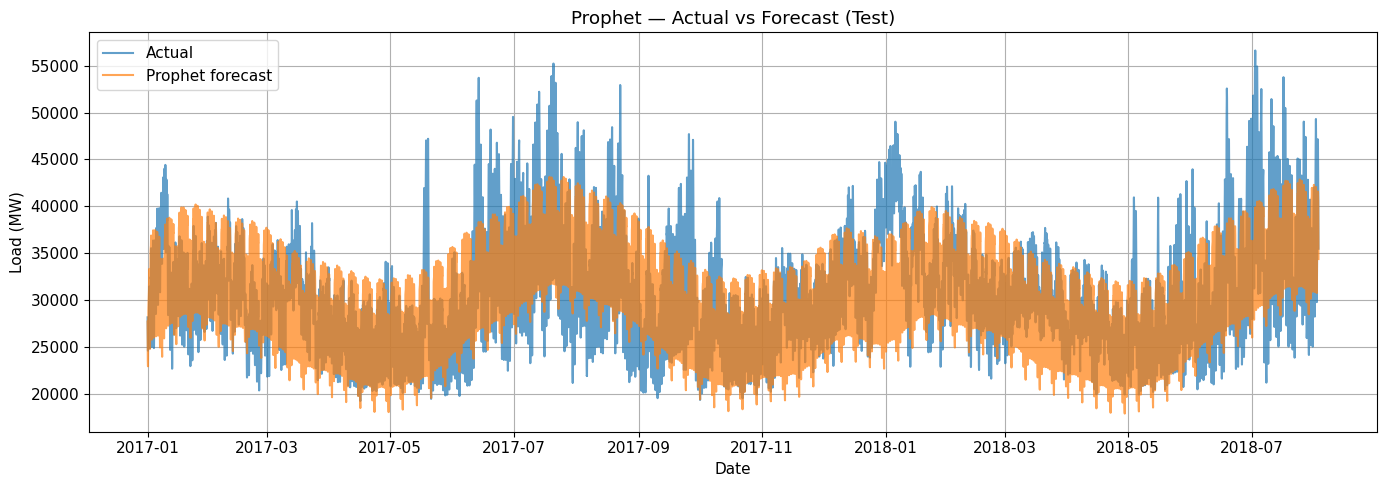

In [195]:
plt.figure(figsize=(14,5))
plt.plot(eval_df["ds"], eval_df["y"], label="Actual", alpha=0.7)
plt.plot(eval_df["ds"], eval_df["yhat"], label="Prophet forecast", alpha=0.7)
plt.title("Prophet — Actual vs Forecast (Test)")
plt.xlabel("Date")
plt.ylabel("Load (MW)")
plt.legend()
plt.tight_layout()
plt.show()

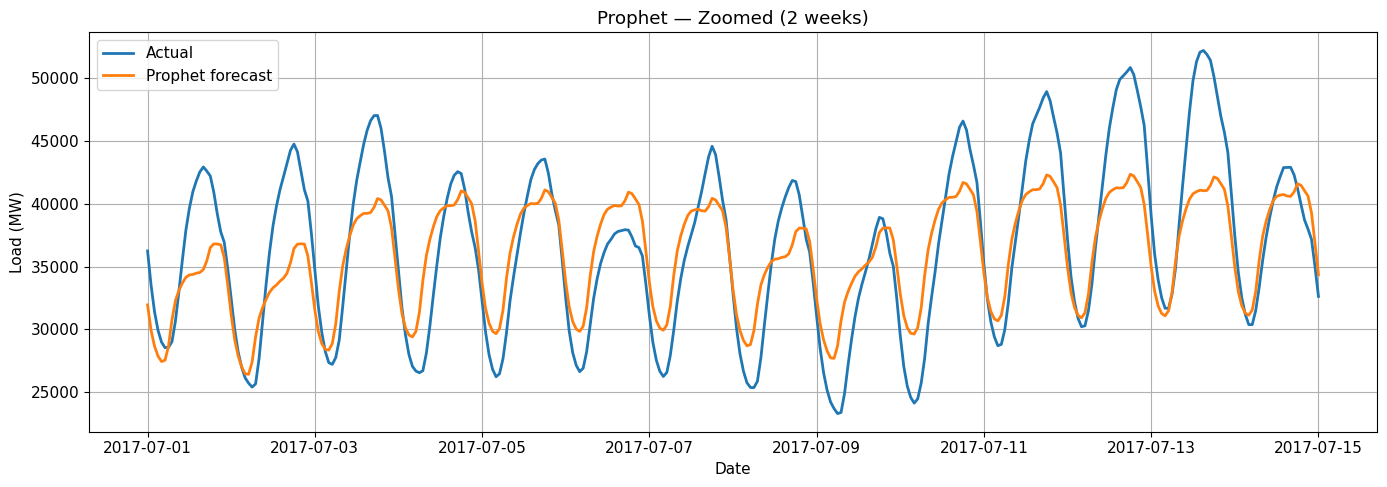

In [196]:
start_date = "2017-07-01"
end_date   = "2017-07-15"

z = eval_df[(eval_df["ds"] >= start_date) & (eval_df["ds"] <= end_date)]

plt.figure(figsize=(14,5))
plt.plot(z["ds"], z["y"], label="Actual", linewidth=2)
plt.plot(z["ds"], z["yhat"], label="Prophet forecast", linewidth=2)
plt.title("Prophet — Zoomed (2 weeks)")
plt.xlabel("Date")
plt.ylabel("Load (MW)")
plt.legend()
plt.tight_layout()
plt.show()

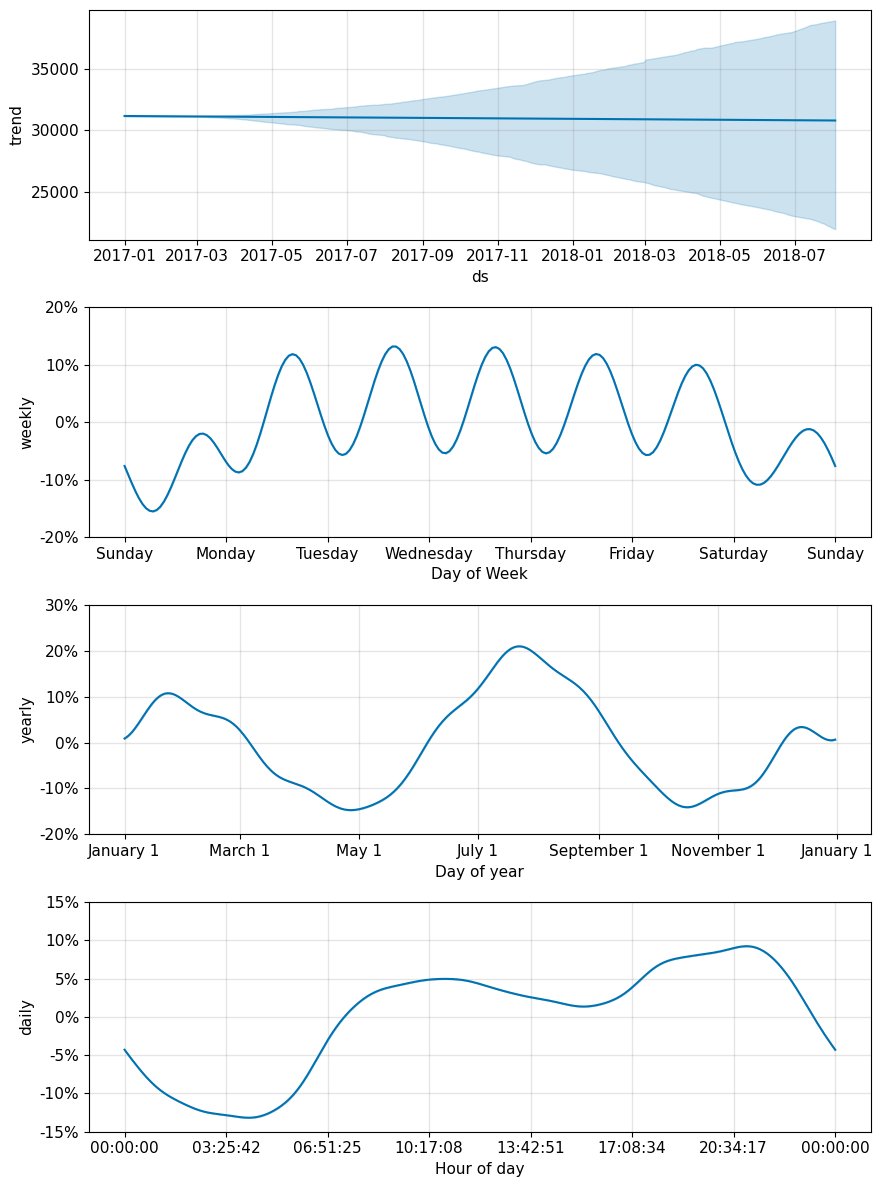

In [201]:
m0.plot_components(fcst)
plt.show()

In [211]:
xgb.save_model("pjm-deployment/xgboost_model.bin")

C:\Users\User\anaconda3\Lib\site-packages\xgboost\core.py:158: UserWarning: [18:53:11] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\c_api\c_api.cc:1374: Saving model in the UBJSON format as default.  You can use file extension: `json`, `ubj` or `deprecated` to choose between formats.
  warnings.warn(smsg, UserWarning)
